In [3]:
import yaml
import warnings

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [4]:
seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'
data_path = Path(config['DATADIR'])

# Syntax: sym_cellline_replicate
cell_line_dict={
    '01': 'H1975',
    '02': 'H1299',
    '03': 'A549'
}

# Target Alignment

## Merging with original data

In [6]:
def parse_sam_file(sam_file):
    data = []
    with open(sam_file, 'r') as f:
        for line in f:
            # Skip header lines if any
            if line.startswith('@'):
                continue
            
            fields = line.strip().split('\t')
            # Extract relevant fields
            query_name = fields[0]
            flag = int(fields[1])
            reference_name = fields[2]
            position = int(fields[3])
            mapq = int(fields[4])
            cigar = fields[5]
            rnext = fields[6]
            pnext = int(fields[7])
            tlen = int(fields[8])
            seq = fields[9]
            qual = fields[10]
            # Additional optional fields
            optional_fields = fields[11:]
            # Store the information
            data.append({'QueryName': query_name, 'Flag': flag, 'ReferenceName': reference_name, 'Position': position,
                         'MappingQuality': mapq, 'CIGAR': cigar, 'RNext': rnext, 'PNext': pnext, 'TLEN': tlen,
                         'Sequence': seq, 'Quality': qual, 'OptionalFields': optional_fields})
    return data

def process_alignment(sam_path):
    alignment = pd.DataFrame(parse_sam_file(sam_path)).set_index('QueryName')

    # Annotate strand
    alignment['strand'] = None
    alignment['strand'][(alignment['Flag'] == 16) | (alignment['Flag'] == 272)] = '-'
    alignment['strand'][(alignment['Flag'] == 0) | (alignment['Flag'] == 256)] = '+'
    # Remove and rename columns
    alignment.drop(['RNext', 'PNext', 'TLEN', 'OptionalFields'], inplace=True, axis=1)
    alignment.rename(columns={'ReferenceName': 'chromosome', 'Position': 'Start_position'}, inplace=True)
    alignment.index.name = 'guide_id'
    # Calculate end position
    alignment['End_position'] = alignment['Start_position'] + alignment['Sequence'].str.len()
    # Remove unmapped reads
    alignment = alignment[alignment['Flag'] != 4]

    alignment = alignment.sort_values('MappingQuality', ascending=False)
    salignment = alignment[~alignment.index.duplicated(keep='first')]
    guide_df = pd.read_csv('../resources/all_gRNA_data.csv', index_col='unique_guide_name')
    tab = pd.merge(guide_df, salignment, left_index=True, right_index=True, how='left')
    
    return tab

In [7]:
tab = process_alignment("/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/guides_aligned_to_genome.sam")
tab.to_csv('../resources/guide_alignment_dna_v1.csv')

tab_ = process_alignment("/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/guides_aligned_to_transcriptome.sam")
tab_.to_csv('../resources/guide_alignment_transcriptome_v1.csv')

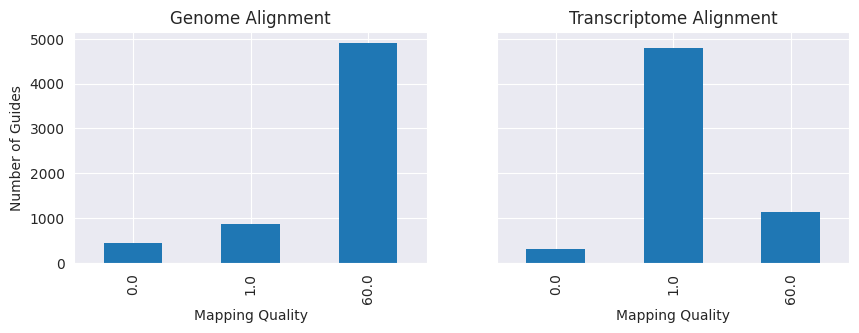

In [8]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(10, 3), sharey=True)
ax = axs[0]
tab.MappingQuality.fillna(0).value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set_title('Genome Alignment')
ax.set_ylabel('Number of Guides')

ax = axs[1]
tab_.MappingQuality.fillna(0).value_counts().sort_index().plot(kind='bar')
ax.set_title('Transcriptome Alignment')

for ax in axs:
    ax.set_xlabel('Mapping Quality')
    ax.grid(True)
pl.show()

## Annotate exon numbers (moved to snakemake)

- Parse the alignment results (SAM/BAM files) to extract the alignment positions (chromosome, start, end).
- Load the transcript annotation file (GTF/GFF) into memory.
- For each alignment position, check which transcripts it overlaps with based on genomic coordinates.
- Determine the exon(s) within the transcript that the alignment overlaps with.

In [60]:
alignment = pd.DataFrame(parse_sam_file("/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/guides_aligned_to_genome.sam")).set_index('QueryName')
alignment['End'] = alignment['Position'] + alignment['Sequence'].str.len()

In [10]:
# read gtf file (is this the right one??)
from gtfparse import read_gtf
gtf = read_gtf('/g/huber/users/peidli/utils/genomes/homo_sapiens/Homo_sapiens.GRCh38.111.gtf')
gtf = pd.DataFrame(gtf, columns=gtf.columns)

INFO:root:Extracted GTF attributes: ['gene_id', 'gene_version', 'gene_name', 'gene_source', 'gene_biotype', 'transcript_id', 'transcript_version', 'transcript_name', 'transcript_source', 'transcript_biotype', 'tag', 'transcript_support_level', 'exon_number', 'exon_id', 'exon_version', 'protein_id', 'protein_version', 'ccds_id']


In [11]:
alignment

,Flag,ReferenceName,Position,MappingQuality,CIGAR,RNext,PNext,TLEN,Sequence,Quality,OptionalFields,End
QueryName,,,,,,,,,,,,
CYP26B1_ENST00000001146_2702,0,2,72131268,60,23M,*,0,0,TTAAACCCAAATAATGCCCGGAG,IIIIIIIIIIIIIIIIIIIIIII,"[AS:i:0, XN:i:0, XM:i:0, XO:i:0, XG:i:0, NM:i:...",72131291
RPS20_ENST00000009589_544,0,8,56073029,60,23M,*,0,0,TATTCTGAATAAAAACCAACAGA,IIIIIIIIIIIIIIIIIIIIIII,"[AS:i:0, XN:i:0, XM:i:0, XO:i:0, XG:i:0, NM:i:...",56073052
NDUFAB1_ENST00000007516_654,0,16,23581065,60,23M,*,0,0,AAGTCCATCAGAATCACTCTGTC,IIIIIIIIIIIIIIIIIIIIIII,"[AS:i:0, XN:i:0, XM:i:0, XO:i:0, XG:i:0, NM:i:...",23581088
COX15_ENST00000016171_2286,0,10,99713585,60,23M,*,0,0,ATTACAAAGCTGTTAGGAAACCC,IIIIIIIIIIIIIIIIIIIIIII,"[AS:i:0, XN:i:0, XM:i:0, XO:i:0, XG:i:0, NM:i:...",99713608
AQR_ENST00000156471_5156,0,15,34856320,60,23M,*,0,0,AATATCTTTACATAAAGACAGCA,IIIIIIIIIIIIIIIIIIIIIII,"[AS:i:0, XN:i:0, XM:i:0, XO:i:0, XG:i:0, NM:i:...",34856343
...,...,...,...,...,...,...,...,...,...,...,...,...
NT_Control_rc_000400_NA,4,*,0,0,*,*,0,0,ATCTCGTCGTGCTTTATTATAGT,IIIIIIIIIIIIIIIIIIIIIII,[YT:Z:UU],23
NT_Control_rc_001028_NA,4,*,0,0,*,*,0,0,GCGACTACGGTGTATGCATTCCA,IIIIIIIIIIIIIIIIIIIIIII,[YT:Z:UU],23
NT_Control_rc_000043_NA,4,*,0,0,*,*,0,0,ATCGACCGACCGTGAAGATACAC,IIIIIIIIIIIIIIIIIIIIIII,[YT:Z:UU],23


In [12]:
# Problem: I find multiple exons at the same location
best_hits = {}
for i in tqdm(range(len(alignment))):
    if alignment.iloc[i, 3] == 0: # 'MappingQuality'
        best_hits[i] = None
        continue
    ref, start, end = alignment.iloc[i, [1, 2, -1]]
    sgtf = gtf[(gtf.seqname==ref) & (gtf.feature == 'exon')]
    is_overlapping = (((sgtf.start < start) & (sgtf.end > start)) | ((sgtf.start < end) & (sgtf.end > end)))
    sgtf = sgtf[is_overlapping]
    exons = sgtf.exon_number.unique()
    if len(exons) == 0:
        # no matching exon
        exon_number = None
    elif len(exons) == 1:
        # exactly one exon matching
        exon_number = exons[0]
    elif len(exons) > 1:
        # Multiple different exon numbers for position were found
        if len(sgtf.exon_version) > 1:
            # Take most recent exon version
            sgtf_ordered = sgtf.sort_values('exon_version', ascending=False)
        # Now we just take the first exon number
        exon_number = sgtf_ordered.exon_number.iloc[0]
    best_hits[i] = exon_number
    if i>10: break

  0%|          | 11/8001 [00:06<1:17:05,  1.73it/s]


In [28]:
print('Unique exon numbers: ', len(pd.unique(best_hits.values())))
s = pd.Series(best_hits, name='exon_number')
s.to_csv('exon_numbers.csv')

Unique exon numbers:  1


In [68]:
for feature in ['genome', 'transcriptome']:
    dat = pd.read_csv(f'/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/guides_aligned_to_{feature}_annotated.csv', index_col=0).drop(['RNext', 'CIGAR', 'TLEN', 'PNext', 'Quality', 'OptionalFields'], axis=1).rename(columns={'ReferenceName': 'chromosome', 'Position': 'Start_position', 'End': 'End_position'})
    dat.to_csv(f'../results/tables/guide_alignment_{feature}.csv')

# Analyse CRISPRcleanR output

In [93]:
import pycircos
import collections
cell_lines = ['H1975', 'H1299', 'A549']

In [94]:
cell_line = cell_lines[1]

In [86]:
segments = pd.read_csv(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_segments.csv', index_col=0)
corr_lfc = pd.read_csv(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_corrected_logFCs.csv', index_col=0)

In [87]:
corr_lfc

,CHR,startp,endp,genes,avgFC,BP,correction,correctedFC,guideIdx
ATAD3B_ENST00000308647_1564,1,1490367,1490390,ATAD3B,-0.789646,1490378.5,-1,-0.635977,1
ATAD3B_ENST00000308647_1568,1,1490371,1490394,ATAD3B,-1.252854,1490382.5,-1,-1.099185,2
ATAD3B_ENST00000308647_1571,1,1490374,1490397,ATAD3B,-1.618066,1490385.5,-1,-1.464397,3
ATAD3B_ENST00000308647_2408,1,1496162,1496185,ATAD3B,0.249316,1496173.5,-1,0.402985,4
ATAD3B_ENST00000308647_2410,1,1496164,1496187,ATAD3B,0.245455,1496175.5,-1,0.399124,5
...,...,...,...,...,...,...,...,...,...
TMLHE_ENST00000334398_462,23,155524498,155524521,TMLHE,0.129090,155524509.5,1,0.390070,143
TMLHE_ENST00000369439_45,23,155612833,155612856,TMLHE,0.323944,155612844.5,1,0.584925,144
TMLHE_ENST00000369439_44,23,155612834,155612857,TMLHE,-0.129326,155612845.5,1,0.131655,145
TMLHE_ENST00000334398_43,23,155612894,155612917,TMLHE,0.547325,155612905.5,1,0.808305,146


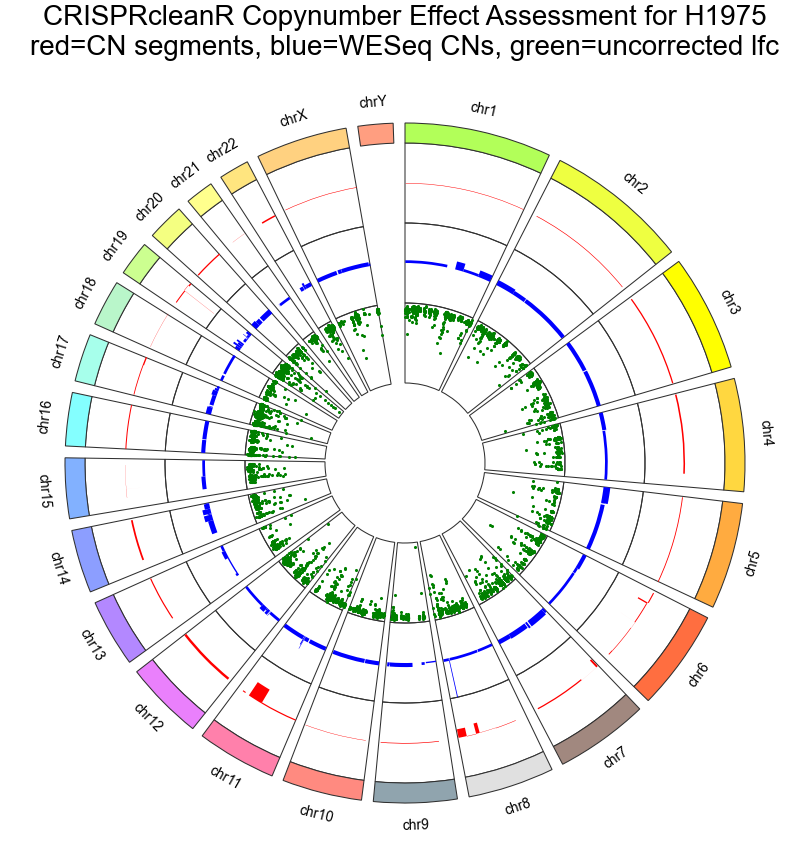

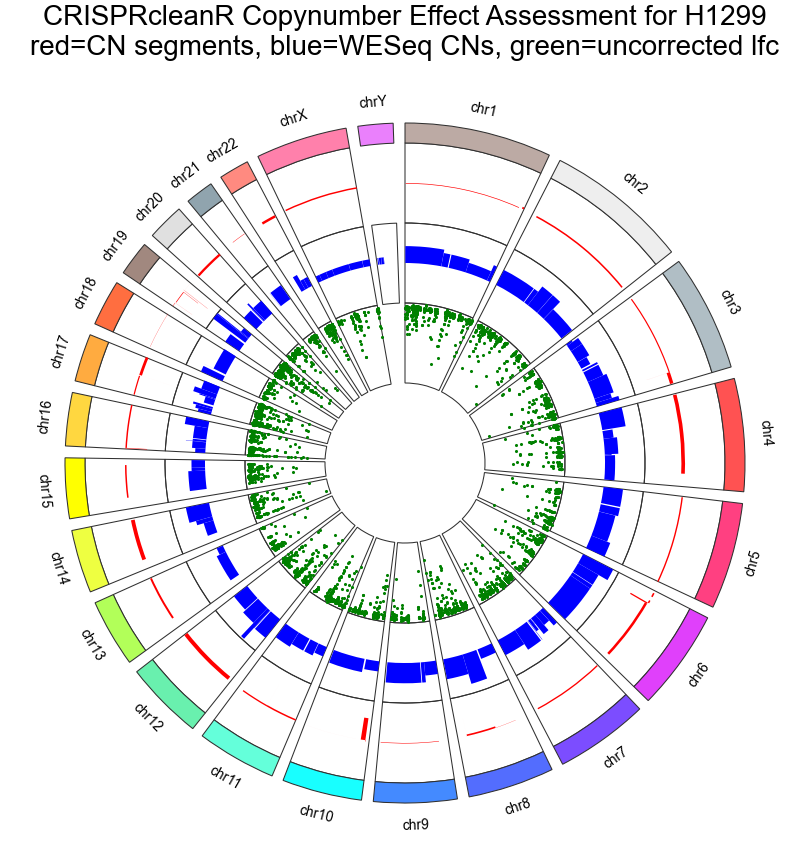

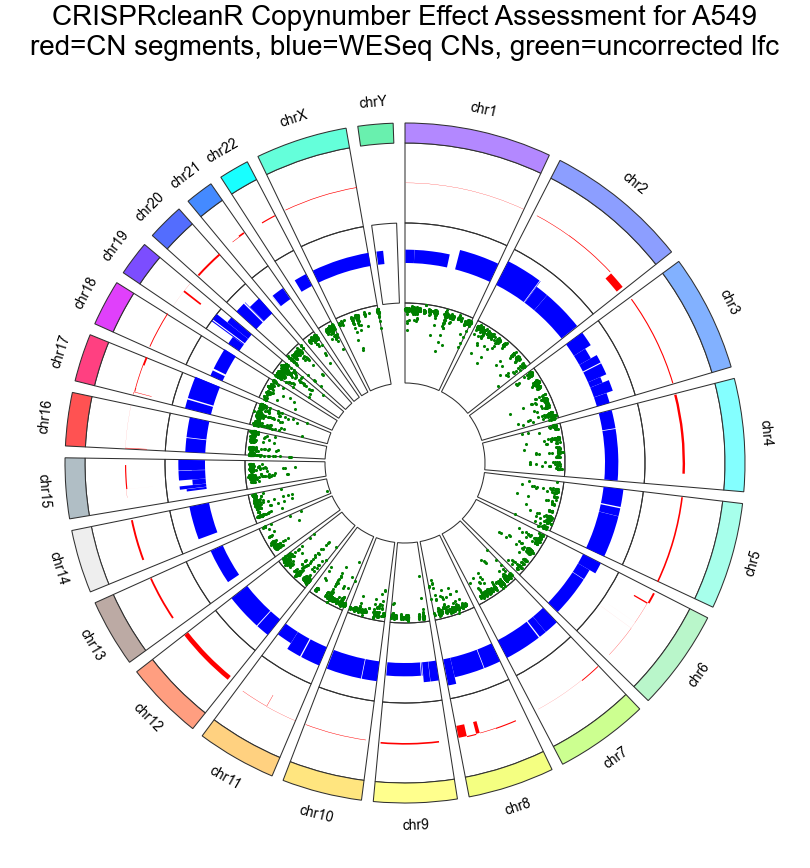

In [110]:
for cell_line in cell_lines:

    #Set chromosomes
    Garc    = pycircos.Garc
    Gcircle = pycircos.Gcircle
    circle = Gcircle(figsize=(8,8)) 
    with open("../utils/pycircos_example_data_chromosome_general.csv") as f:
        f.readline()
        for line in f:
            line   = line.rstrip().split(",") 
            name   = line[0]
            length = int(line[-1]) 
            arc    = Garc(arc_id=name, size=length, interspace=2, raxis_range=(800,850), labelposition=80, label_visible=True)
            circle.add_garc(arc)
    circle.set_garcs(0,360) 

    #bar plot for segments
    values_all   = [] 
    arcdata_dict = collections.defaultdict(dict)
    with open(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_segments.csv') as f:
        f.readline()
        for line in f:
            line  = line.rstrip().split(",")
            name  = 'chr' + line[1] if int(line[1]) < 23 else 'chrX' if int(line[1]) == 23 else 'chrY'
            start = int(line[2])-1
            end   = int(line[3]) 
            width = end-start 
            if name not in arcdata_dict:
                arcdata_dict[name]["positions"] = []
                arcdata_dict[name]["widths"]    = [] 
                arcdata_dict[name]["values"]    = [] 
            arcdata_dict[name]["positions"].append(start) 
            arcdata_dict[name]["widths"].append(width)
            arcdata_dict[name]["values"].append(float(line[5]))
            values_all.append(float(line[5]))
    m = np.max(np.abs(values_all))
    for key in arcdata_dict:  
        circle.barplot(key, 
                    data=arcdata_dict[key]["values"], 
                    positions=arcdata_dict[key]["positions"], 
                    width=arcdata_dict[key]["widths"], 
                    base_value=0.0, 
                    rlim=[-m, m],
                    raxis_range=[600,800], 
                    facecolor="r", spine=True)
    
    # CNV profile from WESeq
    values_all   = [] 
    arcdata_dict = collections.defaultdict(dict)
    with open(f'../resources/CNV_profiles/{cell_line}_pureCN_CNV_segments.csv') as f:
        f.readline()
        for line in f:
            line  = line.rstrip().split(",")
            name  = line[2]
            start = int(line[3])-1
            end   = int(line[4]) 
            width = end-start 
            if name not in arcdata_dict:
                arcdata_dict[name]["positions"] = []
                arcdata_dict[name]["widths"]    = [] 
                arcdata_dict[name]["values"]    = [] 
            arcdata_dict[name]["positions"].append(start) 
            arcdata_dict[name]["widths"].append(width)
            val = float(line[6]) if line[6] != '' else 2.0
            arcdata_dict[name]["values"].append(val)
            values_all.append(val)
    m = np.max(np.abs(values_all))
    for key in arcdata_dict:  
        circle.barplot(key, 
                    data=arcdata_dict[key]["values"], 
                    positions=arcdata_dict[key]["positions"], 
                    width=arcdata_dict[key]["widths"], 
                    base_value=0.0, 
                    rlim=[-m, m],
                    raxis_range=[400,600], 
                    facecolor="b", spine=True)
        
    #scatter plot for lfcs
    values_all   = [] 
    arcdata_dict = collections.defaultdict(dict)
    with open(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/{cell_line}_corrected_logFCs.csv') as f:
        f.readline()
        for line in f:
            line  = line.rstrip().split(",")
            name  = 'chr' + line[1] if int(line[1]) < 23 else 'chrX' if int(line[1]) == 23 else 'chrY'
            start = int(line[2])-1
            end   = int(line[3]) 
            mid   = (start+end)/2
            value = float(line[5]) 
            values_all.append(value) 
            if name not in arcdata_dict:
                arcdata_dict[name]["positions"] = []
                arcdata_dict[name]["values"] = []
            arcdata_dict[name]["positions"].append(mid) 
            arcdata_dict[name]["values"].append(value)
    vmin, vmax = min(values_all), max(values_all) 
    for key in arcdata_dict:
        circle.scatterplot(key, 
                        data=arcdata_dict[key]["values"], 
                        positions=arcdata_dict[key]["positions"], 
                        rlim=[vmin-0.05*abs(vmin), vmax+0.05*abs(vmax)], 
                        raxis_range=(200,400), 
                        facecolor="green", spine=True) 

    pl.title('CRISPRcleanR Copynumber Effect Assessment for ' + cell_line +'\nred=CN segments, blue=WESeq CNs, green=uncorrected lfc', fontsize=20)
    pl.savefig(f'../results/figures/crisprcleanr_{cell_line}.pdf', bbox_inches='tight')
    pl.show()

In [114]:
#Set chromosomes
Garc    = pycircos.Garc
Gcircle = pycircos.Gcircle
circle = Gcircle(figsize=(8,8)) 
with open("../utils/pycircos_example_data_chromosome_general.csv") as f:
    f.readline()
    for line in f:
        line   = line.rstrip().split(",") 
        name   = line[0]
        length = int(line[-1]) 
        arc    = Garc(arc_id=name, size=length, interspace=2, raxis_range=(800,850), labelposition=80, label_visible=True)
        circle.add_garc(arc)
circle.set_garcs(0,360) 

#bar plot for segments
values_all   = [] 
arcdata_dict = collections.defaultdict(dict)
with open(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/example_Brunello/HT29_segments.csv') as f:
    f.readline()
    for line in f:
        line  = line.rstrip().split(",")
        name  = 'chr' + line[1] if int(line[1]) < 23 else 'chrX' if int(line[1]) == 23 else 'chrY'
        start = int(line[2])-1
        end   = int(line[3]) 
        width = end-start 
        if name not in arcdata_dict:
            arcdata_dict[name]["positions"] = []
            arcdata_dict[name]["widths"]    = [] 
            arcdata_dict[name]["values"]    = [] 
        arcdata_dict[name]["positions"].append(start) 
        arcdata_dict[name]["widths"].append(width)
        arcdata_dict[name]["values"].append(float(line[5]))
        values_all.append(float(line[5]))
m = np.max(np.abs(values_all))
for key in arcdata_dict:  
    circle.barplot(key, 
                data=arcdata_dict[key]["values"], 
                positions=arcdata_dict[key]["positions"], 
                width=arcdata_dict[key]["widths"], 
                base_value=0.0, 
                rlim=[-m, m],
                raxis_range=[600,800], 
                facecolor="r", spine=True)
    
#scatter plot for lfcs
values_all   = [] 
arcdata_dict = collections.defaultdict(dict)
with open(f'/scratch/peidli/SYMPHONY/pooled_screen_1/crisprcleanr/example_Brunello/HT29_corrected_logFCs.csv') as f:
    f.readline()
    for line in f:
        line  = line.rstrip().split(",")
        name  = 'chr' + line[1] if int(line[1]) < 23 else 'chrX' if int(line[1]) == 23 else 'chrY'
        start = int(float(line[2]))-1
        end   = int(line[3]) 
        mid   = (start+end)/2
        value = float(line[5]) 
        values_all.append(value) 
        if name not in arcdata_dict:
            arcdata_dict[name]["positions"] = []
            arcdata_dict[name]["values"] = []
        arcdata_dict[name]["positions"].append(mid) 
        arcdata_dict[name]["values"].append(value)
vmin, vmax = min(values_all), max(values_all) 
for key in arcdata_dict:
    circle.scatterplot(key, 
                    data=arcdata_dict[key]["values"], 
                    positions=arcdata_dict[key]["positions"], 
                    rlim=[vmin-0.05*abs(vmin), vmax+0.05*abs(vmax)], 
                    raxis_range=(400,600), 
                    facecolor="green", spine=True) 

pl.title('CRISPRcleanR Copynumber Effect Assessment for Brunello et al.\nred=segments, green=uncorrected lfc', fontsize=20)
# pl.savefig(f'../results/figures/crisprcleanr_Brunello.pdf', bbox_inches='tight')
pl.show()

KeyboardInterrupt: 

In [113]:
m

7.9931